<a href="https://colab.research.google.com/github/ibrahimu-shaffy/COU07506-labs_240242491389/blob/main/COU07506_Week04_240242491389.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DIGITAL SIGNAL PROCESSING

## WEEK 04 — LAB 3

### z-Transform Laboratory: Poles, Zeros and Stability

**Name:** SHAFIYU SWALEHE IBRAHIMU

**Registration Number:** 240242491389


**Module Code:** COU 07506

## Objectives

- Determine poles, zeros and frequency response.
- Compute the inverse z-transform using residuez.
- Investigate system stability and resonance.
- Design a simple resonator by placing poles.

In [26]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

plt.rcParams["figure.figsize"] = (9, 3.5)

print("Libraries imported successfully!")

Libraries imported successfully!


## Task 4.1 — A Pole-Zero Plotting Function

This experiment investigates the location of poles
and zeros in the z-plane, frequency response,
and system stability.

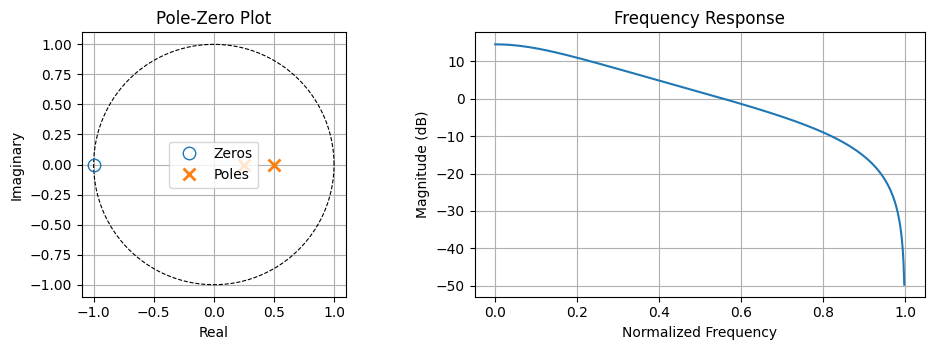

Poles: [0.5  0.25]
Zeros: [-1.]
Stable: True


In [27]:
def zplane(b, a, ax=None):
    z, p, k = signal.tf2zpk(b, a)
    ax = ax or plt.gca()

    th = np.linspace(0, 2*np.pi, 400)

    ax.plot(np.cos(th), np.sin(th), "k--", lw=0.8)
    ax.plot(z.real, z.imag, "o", mfc="none", ms=9, label="Zeros")
    ax.plot(p.real, p.imag, "x", ms=9, mew=2, label="Poles")

    ax.set_aspect("equal")
    ax.legend()
    ax.set_xlabel("Real")
    ax.set_ylabel("Imaginary")
    ax.set_title("Pole-Zero Plot")
    ax.grid(True)

    return z, p

b = [1, 1]
a = [1, -0.75, 0.125]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.6))

z, p = zplane(b, a, ax1)

w, H = signal.freqz(b, a, worN=512)

ax2.plot(w/np.pi, 20*np.log10(np.abs(H)))
ax2.set_xlabel("Normalized Frequency")
ax2.set_ylabel("Magnitude (dB)")
ax2.set_title("Frequency Response")
ax2.grid(True)

plt.tight_layout()
plt.show()

print("Poles:", p)
print("Zeros:", z)
print("Stable:", np.all(np.abs(p) < 1))

## Observation

The system has two poles at 0.5 and 0.25
and a zero at -1.

Both poles lie inside the unit circle.
Therefore, the causal system is stable.

The frequency response decreases towards
the Nyquist frequency due to the zero at -1.


## Task 4.2 — Inverse z-Transform with residuez

This experiment uses partial-fraction expansion
to compute the inverse z-transform and verifies
the results using the lfilter function.

In [28]:
r, p, k = signal.residuez([1], [1, -0.75, 0.125])

print("Residues:", r)
print("Poles:", p)

n = np.arange(10)

x_pf = sum(ri * pi**n for ri, pi in zip(r, p)).real

impulse = np.zeros(10)
impulse[0] = 1

x_lf = signal.lfilter([1], [1, -0.75, 0.125], impulse)

print("Results match:", np.allclose(x_pf, x_lf))

Residues: [-1.  2.]
Poles: [0.25 0.5 ]
Results match: True


Residues: [-5.  6.]
Poles: [0.25 0.5 ]
Results match: True


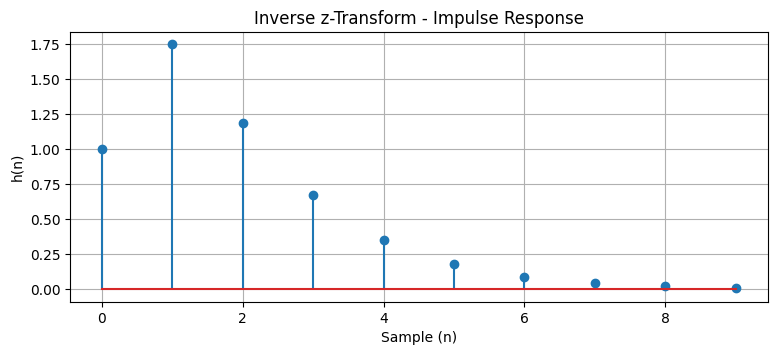

In [29]:
r, p, k = signal.residuez([1, 1], [1, -0.75, 0.125])

print("Residues:", r)
print("Poles:", p)

n = np.arange(10)

h = sum(ri * pi**n for ri, pi in zip(r, p)).real

h_theory = 6*(0.5)**n - 5*(0.25)**n

print("Results match:", np.allclose(h, h_theory))

plt.stem(n, h)
plt.title("Inverse z-Transform - Impulse Response")
plt.xlabel("Sample (n)")
plt.ylabel("h(n)")
plt.grid(True)
plt.show()

## Observation

The residues obtained using residuez agree with
the pre-lab partial-fraction calculations.

For the second system, the impulse response is:

$$
h(n)=[6(0.5)^n-5(0.25)^n]u(n)
$$

The calculated and theoretical results are equal.
The impulse response decays towards zero,
confirming that the causal system is stable.

## Task 4.3 — Pole Position and the Impulse Response

This experiment investigates how the pole radius
affects the impulse response, frequency response
and stability of a discrete-time system.

The denominator is given by:

$$
A(z)=1-2r\cos(\pi/4)z^{-1}+r^2z^{-2}
$$

r = 0.5, Stable: True
r = 0.8, Stable: True
r = 0.95, Stable: True
r = 1.0, Stable: False
r = 1.05, Stable: False


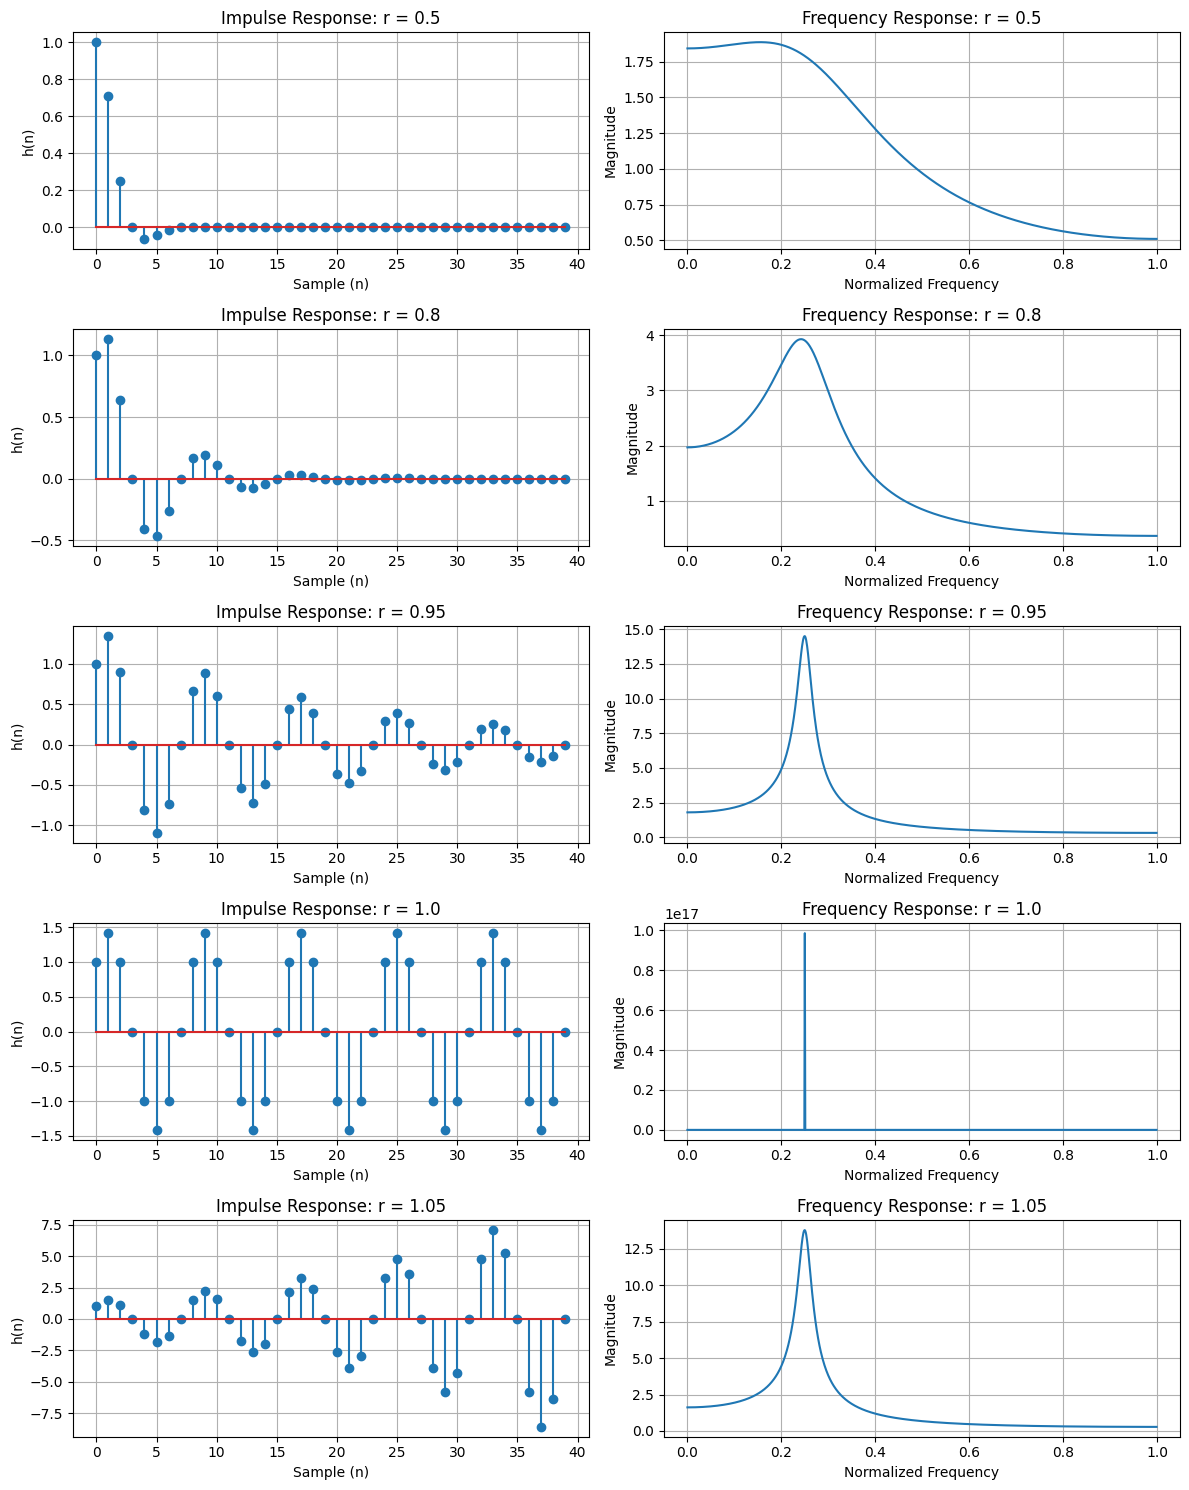

In [30]:
r_values = [0.5, 0.8, 0.95, 1.0, 1.05]
theta = np.pi/4

n = np.arange(40)

impulse = np.zeros(40)
impulse[0] = 1

fig, ax = plt.subplots(5, 2, figsize=(12, 15))

for i, r in enumerate(r_values):

    b = [1]
    a = [1, -2*r*np.cos(theta), r**2]

    h = signal.lfilter(b, a, impulse)
    w, H = signal.freqz(b, a, worN=1024)

    ax[i, 0].stem(n, h)
    ax[i, 0].set_title(f"Impulse Response: r = {r}")
    ax[i, 0].set_xlabel("Sample (n)")
    ax[i, 0].set_ylabel("h(n)")
    ax[i, 0].grid(True)

    ax[i, 1].plot(w/np.pi, np.abs(H))
    ax[i, 1].set_title(f"Frequency Response: r = {r}")
    ax[i, 1].set_xlabel("Normalized Frequency")
    ax[i, 1].set_ylabel("Magnitude")
    ax[i, 1].grid(True)

    print(f"r = {r}, Stable: {r < 1}")

plt.tight_layout()
plt.show()

## Observation

- At r = 0.5, the impulse response decays rapidly.
- At r = 0.8, the impulse response decays more slowly.
- At r = 0.95, oscillations last longer and the
  frequency response has a sharper resonance peak.
- At r = 1.0, oscillations continue without decay.
- At r = 1.05, the impulse response grows with time.

The oscillation frequency remains unchanged because
the pole angle is constant at pi/4.

The systems with r = 0.5, 0.8 and 0.95 are stable,
while r = 1.0 and 1.05 are not BIBO stable.

## Task 4.4 — Stability of Given Systems

This experiment classifies four discrete-time
systems as stable or unstable using pole-zero
diagrams and impulse responses.

The given systems are:

$$
H_1(z)=\frac{1}{1-1.6z^{-1}+0.89z^{-2}}
$$

$$
H_2(z)=\frac{1+z^{-1}}{1-2.5z^{-1}+z^{-2}}
$$

$$
H_3(z)=\frac{1}{1+0.5z^{-1}-0.5z^{-2}}
$$

$$
H_4(z)=1-z^{-4}
$$

System H1
Poles: [0.8+0.5j 0.8-0.5j]
Stable: True

System H2
Poles: [2.  0.5]
Stable: False

System H3
Poles: [-1.   0.5]
Stable: False

System H4
Poles: []
Stable: True



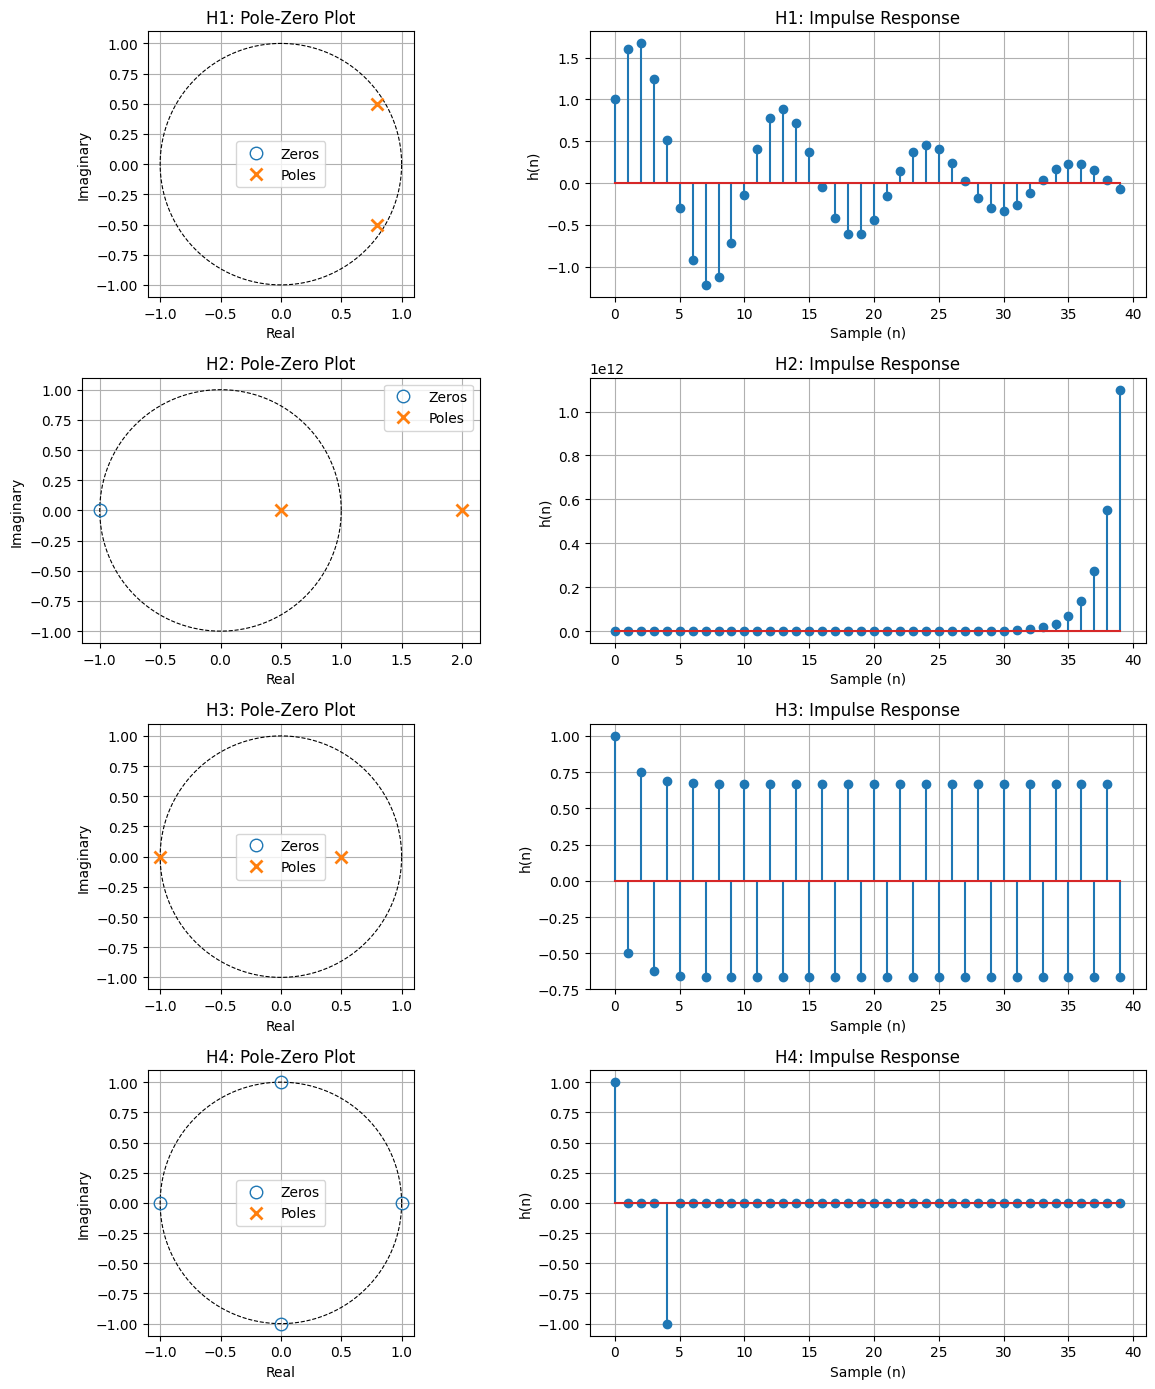

In [31]:
systems = [
    ([1], [1, -1.6, 0.89]),
    ([1, 1], [1, -2.5, 1]),
    ([1], [1, 0.5, -0.5]),
    ([1, 0, 0, 0, -1], [1])
]

n = np.arange(40)
impulse = np.zeros(40)
impulse[0] = 1

fig, ax = plt.subplots(4, 2, figsize=(12, 14))

for i, (b, a) in enumerate(systems):

    z, p = zplane(b, a, ax[i, 0])

    stable = np.all(np.abs(p) < 1)

    h = signal.lfilter(b, a, impulse)

    ax[i, 0].set_title(f"H{i+1}: Pole-Zero Plot")

    ax[i, 1].stem(n, h)
    ax[i, 1].set_title(f"H{i+1}: Impulse Response")
    ax[i, 1].set_xlabel("Sample (n)")
    ax[i, 1].set_ylabel("h(n)")
    ax[i, 1].grid(True)

    print(f"System H{i+1}")
    print("Poles:", p)
    print("Stable:", stable)
    print()

plt.tight_layout()
plt.show()

## Observation

System H1 is stable because both poles lie inside
the unit circle and its impulse response decays.

System H2 is unstable because one pole lies outside
the unit circle and its impulse response grows.

System H3 is not BIBO stable because one pole lies
on the unit circle and oscillations do not decay.

System H4 is stable because it is an FIR system
with a finite impulse response.

## Task 4.5 — Design a Resonator

This experiment designs a second-order resonator
with a resonant frequency of 1000 Hz, a sampling
frequency of 8000 Hz and a pole radius of 0.97.

The pole angle is:

$$
\theta=\frac{2\pi f_0}{f_s}=\frac{\pi}{4}
$$

The transfer function is:

$$
H(z)=\frac{1-z^{-2}}
{1-2r\cos(\theta)z^{-1}+r^2z^{-2}}
$$

Zeros are placed at z = +1 and z = -1 to block
DC and the Nyquist frequency.

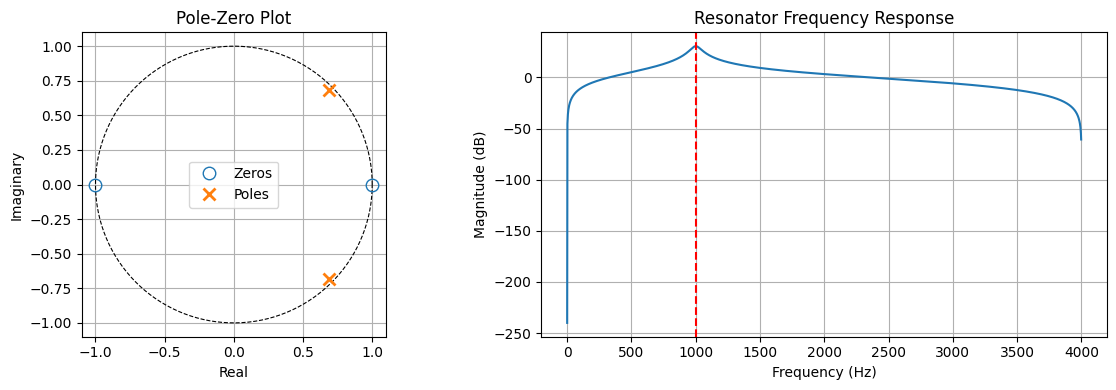

Poles: [0.68589358+0.68589358j 0.68589358-0.68589358j]
Zeros: [-1.  1.]
Stable: True
Peak frequency: 1000.0 Hz
Original White Noise:


Filtered Resonator Audio:


In [32]:
from IPython.display import Audio, display

fs = 8000
f0 = 1000
r = 0.97

theta = 2*np.pi*f0/fs

b = [1, 0, -1]
a = [1, -2*r*np.cos(theta), r**2]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# Pole-zero diagram
z, p = zplane(b, a, ax1)

# Frequency response
f, H = signal.freqz(b, a, worN=2048, fs=fs)

ax2.plot(f, 20*np.log10(np.maximum(np.abs(H), 1e-12)))
ax2.axvline(1000, color="red", linestyle="--")
ax2.set_title("Resonator Frequency Response")
ax2.set_xlabel("Frequency (Hz)")
ax2.set_ylabel("Magnitude (dB)")
ax2.grid(True)

plt.tight_layout()
plt.show()

print("Poles:", p)
print("Zeros:", z)
print("Stable:", np.all(np.abs(p) < 1))
print("Peak frequency:", f[np.argmax(np.abs(H))], "Hz")

# Generate white noise
rng = np.random.default_rng(0)
x = rng.standard_normal(fs*3)

# Apply resonator
y = signal.lfilter(b, a, x)

print("Original White Noise:")
display(Audio(x, rate=fs))

print("Filtered Resonator Audio:")
display(Audio(y, rate=fs))

## Observation

The resonator produces a sharp frequency response
peak near 1000 Hz.

The poles lie inside the unit circle with a radius
of 0.97, confirming that the system is stable.

The zeros at +1 and -1 suppress DC and the
Nyquist frequency.

The filtered white noise contains a dominant
frequency component near 1000 Hz.

## Analysis Questions

### 1. Explain the effect of r on the bandwidth of
the resonance in Task 4.3.

As the pole radius increases towards 1, the
resonance bandwidth decreases and the frequency
response becomes sharper.

A smaller pole radius produces a wider bandwidth
and faster impulse response decay.

### 2. What happens to h(n) when a pole lies exactly
on the unit circle?

The impulse response does not decay to zero.
For the complex pole pair in Task 4.3, oscillations
continue indefinitely with constant amplitude.
The causal system is not BIBO stable.

### 3. Why does placing zeros at z = ±1 make the
resonator a band-pass filter?

The zero at z = +1 blocks the DC component (0 Hz),
while the zero at z = -1 blocks the Nyquist
frequency (4000 Hz).

The poles near the resonant frequency allow
frequencies around 1000 Hz to pass.

### 4. Use the stability triangle to check your
answers to Task 4.4 (a)-(c).

For a second-order denominator:

$$
A(z)=1+a_1z^{-1}+a_2z^{-2}
$$

The stability conditions are:

$$
1+a_1+a_2>0
$$

$$
1-a_1+a_2>0
$$

$$
1-a_2>0
$$

| System | Condition 1 | Condition 2 | Condition 3 | Result |
|---|---:|---:|---:|---|
| H1 | 0.29 | 3.49 | 0.11 | Stable |
| H2 | -0.50 | 4.50 | 0.00 | Unstable |
| H3 | 1.00 | 0.00 | 1.50 | Unstable |

The stability triangle results agree with
the pole-zero analysis in Task 4.4.

## Conclusion

This laboratory demonstrated pole-zero analysis,
inverse z-transform, system stability and
resonator design using Python and SciPy.

The results showed how pole locations influence
the impulse response and frequency response
of discrete-time systems.

## AI-use Statement

ChatGPT was used to assist with Python code
preparation, mathematical explanations,
stability analysis and interpretation of results.
The code was executed in Google Colab.